# LAB ASSIGNMENT 1

In [2]:
# Import the requirement library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

1. Use the dataset CC_Customer_Dataset.csv from Lab Assignment

In [3]:
# Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Inspect dataset
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [4]:
# Inspect dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [5]:
# Check dataset shape
df.shape

(660, 7)

In [6]:
# Feature Slicing
X = df.iloc[:, [2, 3, 4, 5, 6]]

# Display selected features
X.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


In [8]:
# Create StandardScaler object
sc = StandardScaler()

# Transform the features
X_scaled = sc.fit_transform(X)

# Display scaled data
print(X_scaled[:5])

[[ 1.74018685 -1.24922476 -0.86045063 -0.54748969 -1.25153737]
 [ 0.41029254 -0.78758515 -1.47373077  2.5205186   1.89185881]
 [ 0.41029254  1.05897329 -0.86045063  0.13428993  0.1455276 ]
 [-0.12166518  0.13569407 -0.86045063 -0.54748969  0.1455276 ]
 [ 1.74018685  0.59733368 -1.47373077  3.20229822 -0.20373864]]


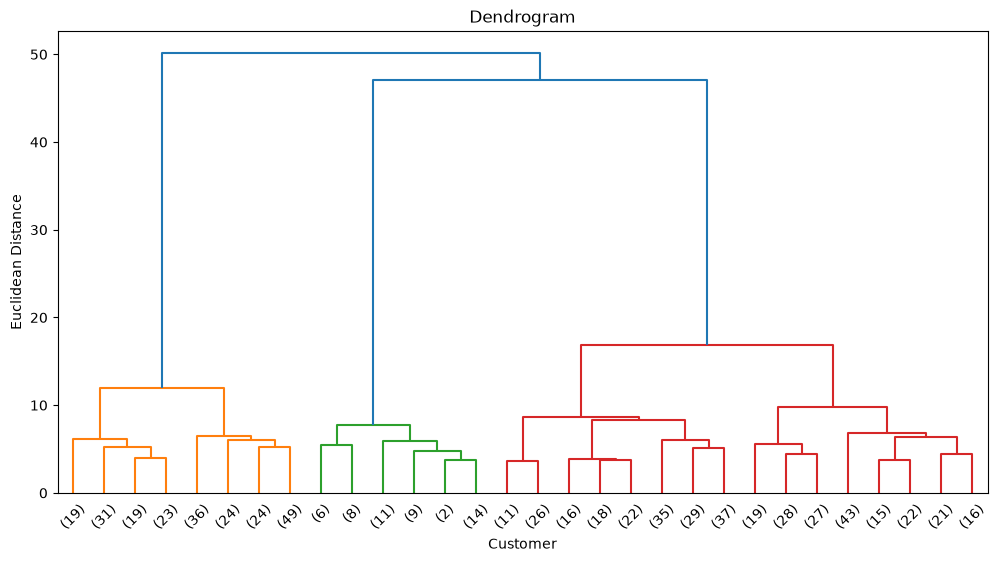

In [9]:
# Create dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    linkage(X_scaled, method='ward'),
    truncate_mode='lastp',
    p=30
)

# Set title and labels
plt.title('Dendrogram')
plt.xlabel('Customer')
plt.ylabel('Euclidean Distance')

plt.show()

2. Construct a clustering model using Agglomerative Clustering with all usable variables.

In [10]:
# Create evaluation list
scores = []

# Experiment with different number of clusters
for i in range(2, 11):

    # Create Agglomerative Clustering model
    hc = AgglomerativeClustering(
        n_clusters=i,
        metric='euclidean',
        linkage='ward'
    )

    # Fit and predict the clusters
    y_hc = hc.fit_predict(X_scaled)

    # Calculate evaluation metrics
    sil_score = silhouette_score(X_scaled, y_hc)
    dbi_score = davies_bouldin_score(X_scaled, y_hc)

    # Store evaluation results
    scores.append([i, sil_score, dbi_score])

# Create evaluation DataFrame
scores_df = pd.DataFrame(
    scores,
    columns=['Clusters', 'Silhouette Score', 'DBI']
)

# Display evaluation results
print(scores_df)

   Clusters  Silhouette Score       DBI
0         2          0.417704  0.932640
1         3          0.514764  0.680960
2         4          0.348082  1.149303
3         5          0.256918  1.385112
4         6          0.226778  1.410876
5         7          0.216297  1.439434
6         8          0.218695  1.448888
7         9          0.195271  1.546620
8        10          0.193142  1.553695


In [11]:
# Determine the best number of clusters
best_k = scores_df.loc[
    scores_df['Silhouette Score'].idxmax(),
    'Clusters'
]

print('Best Number of Clusters:', best_k)

# Create Agglomerative Clustering model
hc = AgglomerativeClustering(
    n_clusters=int(best_k),
    metric='euclidean',
    linkage='ward'
)

# Fit and predict the clusters
y_hc = hc.fit_predict(X_scaled)

# Add cluster labels to the dataset
df['Cluster'] = y_hc

# Display clustering results
print(df.head())

Best Number of Clusters: 3
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  Cluster  
0                  1                    1                 0        0  
1                  0                   10                 9        1  
2                  1                    3                 4        0  
3                  1                    1                 4        0  
4                  0                   12                 3        2  


3. Create a scatterplot based on the dataset using two variables, namely Avg_Credit_Limit and Total_credit_card. Depict the configuration clusterthereof based on these two features.

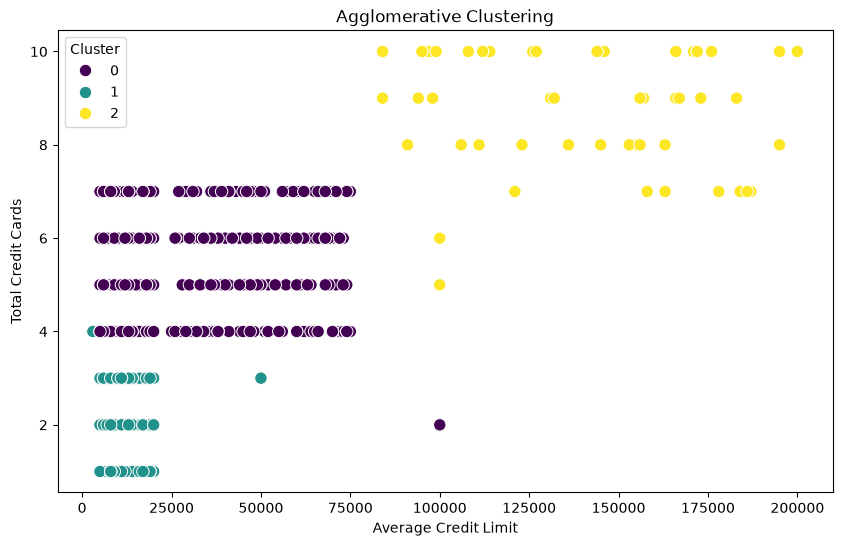

In [12]:
# Visualize the clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Avg_Credit_Limit'],
    y=df['Total_Credit_Cards'],
    hue=df['Cluster'],
    palette='viridis',
    s=80
)

# Set title and labels
plt.title('Agglomerative Clustering')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')

plt.legend(title='Cluster')
plt.show()

4. Determine the value of the silhouette score and the DBI of the model.

In [13]:
# Import silhouette_score
from sklearn.metrics import silhouette_score

# Calculate silhouette score
sil_score = silhouette_score(X_scaled, y_hc)

# Display silhouette score
print('Silhouette Score:', sil_score)

Silhouette Score: 0.5147639589977819


In [14]:
# Import davies_bouldin_score
from sklearn.metrics import davies_bouldin_score

# Calculate Davies-Bouldin Index
dbi_score = davies_bouldin_score(X_scaled, y_hc)

# Display DBI
print('Davies-Bouldin Index:', dbi_score)

Davies-Bouldin Index: 0.680959518994733
